# Random Forest: baseline and tuned classifier
**Review 2 · Classification Part B · target: transmission**

Predict Automatic vs Manual using 2,500 distinct real UK listing records (1,250 per class).
Prices are GBP and distance is miles. Source records come from Aditya Desai's UK used-car dataset;
no synthetic or repeated training rows are added. Distinct rows do not establish VIN-level uniqueness.

The fixed 80:20 stratified split gives 2,000 training rows and 500 test rows, with equal classes in both.
**No oversampling or class weights are needed.** Fit imputation, scaling and encoding inside each fold.
All Part A and B reruns share this new dataset and split; these are not the original Review 1 scores.
The balanced test sample measures performance for this sampled population, not natural market prevalence.

Selection uses **five-fold macro F1**, which gives both classes equal importance. Required weighted
metrics are also reported. The test set is used for the final before/after comparison, never to choose parameters.
The same feature engineering, preprocessing are used before and after tuning.


In [1]:
from pathlib import Path
import sys, os, warnings, json
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if not (ROOT / 'src').exists():
    raise RuntimeError('Open this notebook inside the extracted project/notebooks folder.')
sys.path.insert(0, str(ROOT))
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
%matplotlib inline
sns.set_theme(style='whitegrid', palette='colorblind')
from sklearn.base import clone
from sklearn.model_selection import cross_validate, GridSearchCV
from src.classification import *
raw, df, train, test = load_data()
X_train, y_train = train[RAW_FEATURES], train[TARGET]
X_test, y_test = test[RAW_FEATURES], test[TARGET]
display(pd.DataFrame({'Raw': raw[TARGET].value_counts(), 'Cleaned': df[TARGET].value_counts(),
                      'Train': y_train.value_counts(), 'Test': y_test.value_counts()}))
display(df.dtypes.to_frame('dtype').astype(str))
print('Removed exact duplicate rows:', len(raw) - len(df))
assert not df.duplicated().any()
assert set(train.index).isdisjoint(test.index)


Removed exact duplicate rows: 0


,Raw,Cleaned,Train,Test
transmission,,,,
Automatic,1250,1250,1000,250
Manual,1250,1250,1000,250


,dtype
brand,object
model,object
year,int64
price_gbp,int64
mileage_miles,int64
fuel_type,object
tax_gbp,int64
mpg_uk,float64
engine_size_l,float64
transmission,string


## Training-data audit and EDA
Missing numeric/categorical values, if present, are imputed within each training fold.
Car age uses a fixed reference year (2026); log price/log miles reduce positive skew. Brand, model,
fuel, tax, MPG and engine displacement remain available to the classifier. IQR outliers
are reported and retained rather than deleting legitimate expensive or high-mileage cars.

**Team task:** write your own observations from each plot and justify these feature choices, as required by the guidelines.


Cleaned shape: (2500, 10) | Training: 2000 | Test: 500
Missing training values:
 brand            0
model            0
year             0
price_gbp        0
mileage_miles    0
fuel_type        0
tax_gbp          0
mpg_uk           0
engine_size_l    0
transmission     0
Training IQR outlier counts (retained; log transforms reduce skew):
car_age           38
log_price         22
log_mileage       74
tax_gbp          642
mpg_uk            20
engine_size_l    147


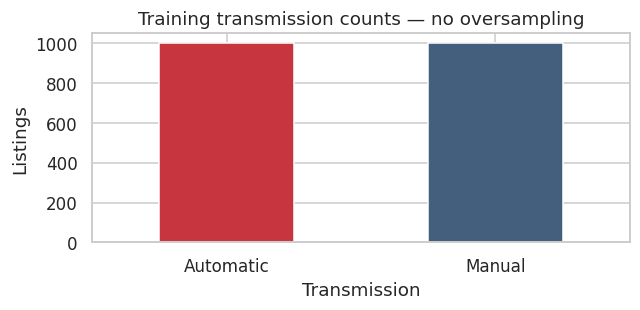

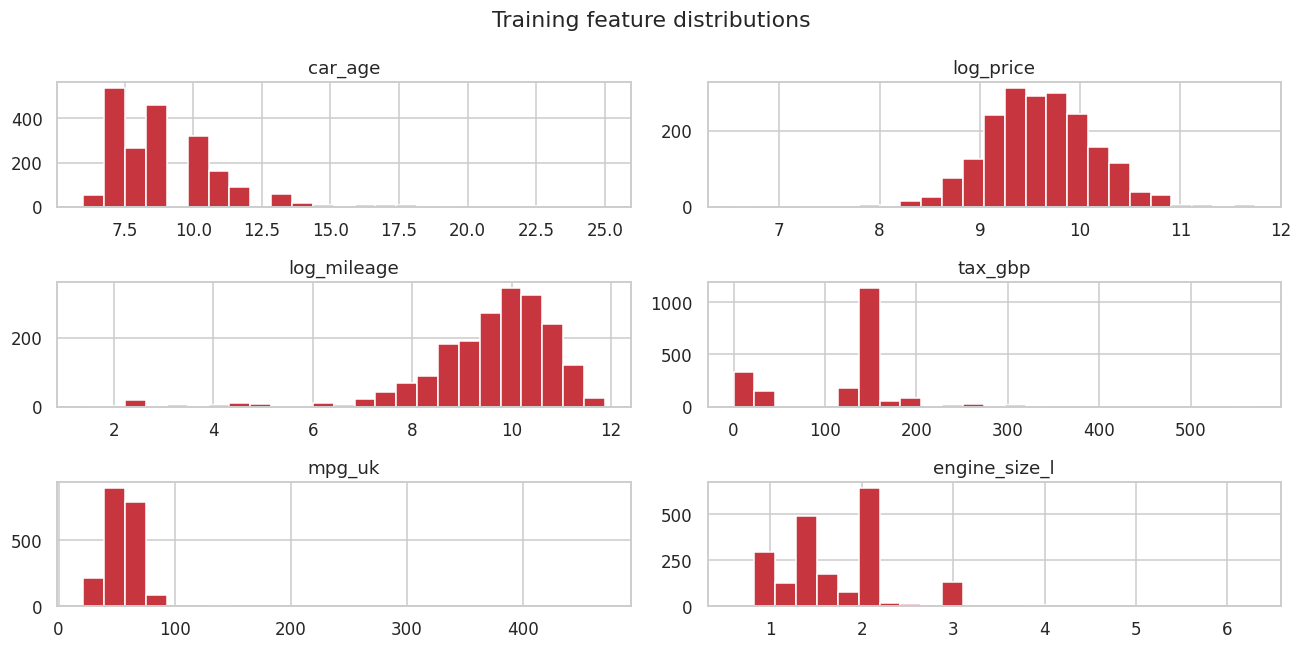

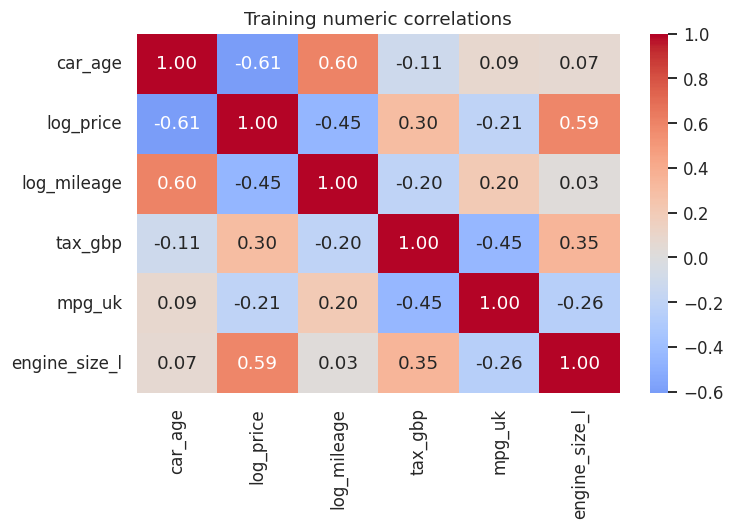

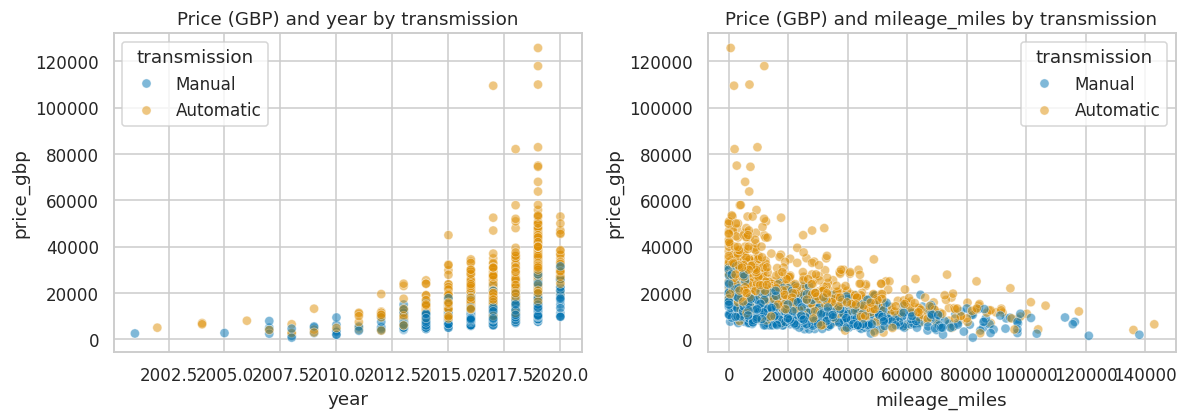

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,2000,9,Ford,312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,2000,143,Fiesta,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,2000.0,NaN,NaN,NaN,2016.9735,2.129569,2001.0,2016.0,2017.0,2019.0,2020.0
price_gbp,2000.0,NaN,NaN,NaN,17001.7955,10392.673128,694.0,10417.25,14492.0,20900.0,125796.0
mileage_miles,2000.0,NaN,NaN,NaN,24529.251,21740.610165,3.0,8121.75,18820.0,34000.0,143000.0
fuel_type,2000,4,Petrol,1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tax_gbp,2000.0,NaN,NaN,NaN,120.4075,67.327468,0.0,125.0,145.0,145.0,570.0
mpg_uk,2000.0,NaN,NaN,NaN,55.725,17.138348,21.4,46.3,55.4,63.15,470.8
engine_size_l,2000.0,NaN,NaN,NaN,1.7235,0.577472,0.6,1.4,1.6,2.0,6.3
transmission,2000,2,Manual,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


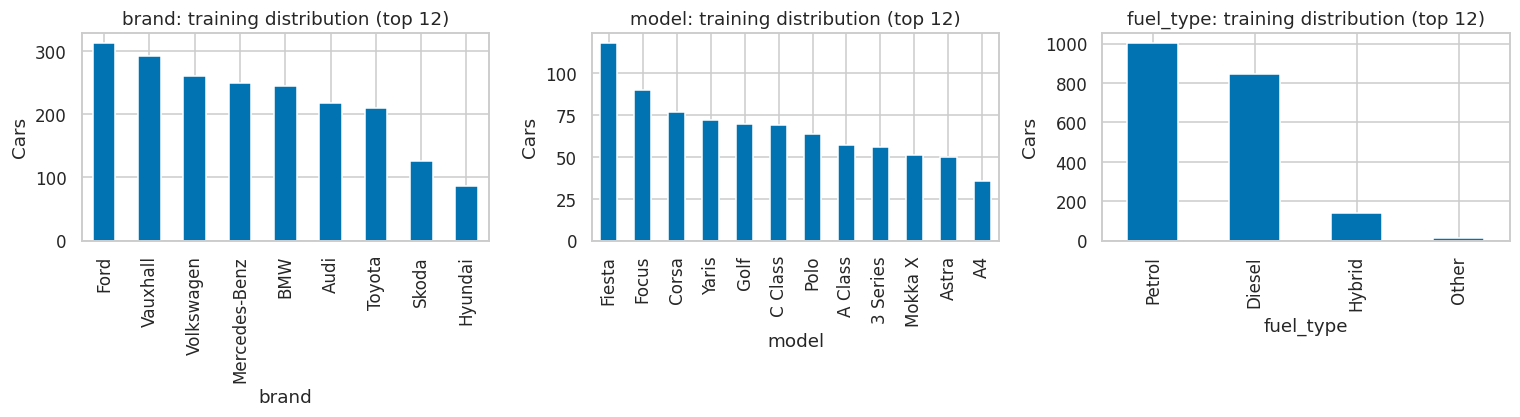

In [2]:
audit_plots(df, train)
display(train.describe(include='all').T)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
features = CarFeatures().transform(X_train)
for ax, col in zip(axes.ravel(), ['brand', 'model', 'fuel_type']):
    features[col].value_counts().head(12).plot.bar(ax=ax)
    ax.set(title=f'{col}: training distribution (top 12)', xlabel=col, ylabel='Cars')
plt.tight_layout(); plt.show()


## Model and search space
The displayed estimator is the untuned baseline. The search includes its parameter settings. A tied or lower test score after tuning is reported honestly.

In [3]:
slug = 'random_forest'
name, estimator, parameter_grid = configurations()[slug]
display(estimator)
display(parameter_grid)
baseline = build_pipeline(clone(estimator))
warning_messages = []


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

[{'model__n_estimators': [100],
  'model__max_depth': [None],
  'model__min_samples_leaf': [1]},
 {'model__n_estimators': [150, 250],
  'model__max_depth': [8, None],
  'model__min_samples_leaf': [2]}]

## Before tuning: five-fold CV and full training fit

In [4]:
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter('always')
    baseline_cv = cross_validate(baseline, X_train, y_train, cv=CV, scoring=SCORING,
                                 n_jobs=1, error_score='raise')
    baseline.fit(X_train, y_train)
warning_messages.extend(str(w.message) for w in captured)
display(pd.DataFrame({k: v for k, v in baseline_cv.items() if k.startswith('test_')}))
print('Mean baseline macro F1:', baseline_cv['test_f1_macro'].mean())


Mean baseline macro F1: 0.8549557420459012


,test_f1_macro,test_f1_weighted,test_balanced_accuracy
0,0.877493,0.877493,0.8775
1,0.852477,0.852477,0.8525
2,0.837418,0.837418,0.8375
3,0.864916,0.864916,0.8650
4,0.842475,0.842475,0.8425


## After tuning: GridSearchCV
Imputation, encoding and scaling are refitted independently inside each fold. The MLP uses a fixed convergence budget without internal early stopping; no test rows are used while fitting.

In [5]:
search = GridSearchCV(build_pipeline(clone(estimator)), parameter_grid,
                      scoring=SCORING, refit='f1_macro', cv=CV,
                      n_jobs=1, error_score='raise', return_train_score=False)
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter('always')
    search.fit(X_train, y_train)
warning_messages.extend(str(w.message) for w in captured)
tuned = search.best_estimator_
print('Best parameters:', search.best_params_)
print('Best training CV macro F1:', search.best_score_)
display(pd.DataFrame(search.cv_results_)[['params', 'mean_test_f1_macro',
    'std_test_f1_macro', 'mean_test_f1_weighted', 'rank_test_f1_macro']].sort_values('rank_test_f1_macro'))
print('Recorded training warnings:', sorted(set(warning_messages)) or 'None')


Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best training CV macro F1: 0.8549557420459012
Recorded training warnings: None


,params,mean_test_f1_macro,std_test_f1_macro,mean_test_f1_weighted,rank_test_f1_macro
0,"{'model__max_depth': None, 'model__min_samples...",0.854956,0.014674,0.854956,1
4,"{'model__max_depth': None, 'model__min_samples...",0.833914,0.021417,0.833914,2
3,"{'model__max_depth': None, 'model__min_samples...",0.832921,0.023248,0.832921,3
1,"{'model__max_depth': 8, 'model__min_samples_le...",0.821478,0.024525,0.821478,4
2,"{'model__max_depth': 8, 'model__min_samples_le...",0.817981,0.027355,0.817981,5


## Held-out test comparison
ROC-AUC and average precision consistently treat **Automatic as positive**. Weighted recall equals accuracy in this single-label task. CV scores used for tuning are selection estimates, not independent generalization estimates.

,Model,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std
0,Random Forest,Before tuning,0.868,0.8692,0.868,0.8679,0.8679,0.868,0.8898,0.84,0.9347,0.9403,0.855,0.0147
1,Random Forest,After tuning,0.868,0.8692,0.868,0.8679,0.8679,0.868,0.8898,0.84,0.9347,0.9403,0.855,0.0147


,After minus before
Accuracy,0.0
F1_weighted,0.0
F1_macro,0.0
Automatic_recall,0.0
ROC_AUC,0.0
CV_macro_F1,0.0


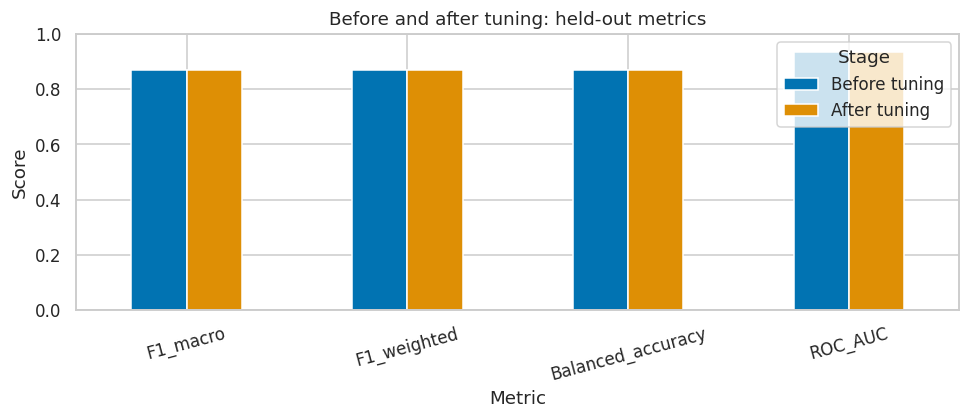

,precision,recall,f1-score,support
Automatic,0.889831,0.840,0.864198,250.000
Manual,0.848485,0.896,0.871595,250.000
accuracy,0.868000,0.868,0.868000,0.868
macro avg,0.869158,0.868,0.867896,500.000
weighted avg,0.869158,0.868,0.867896,500.000


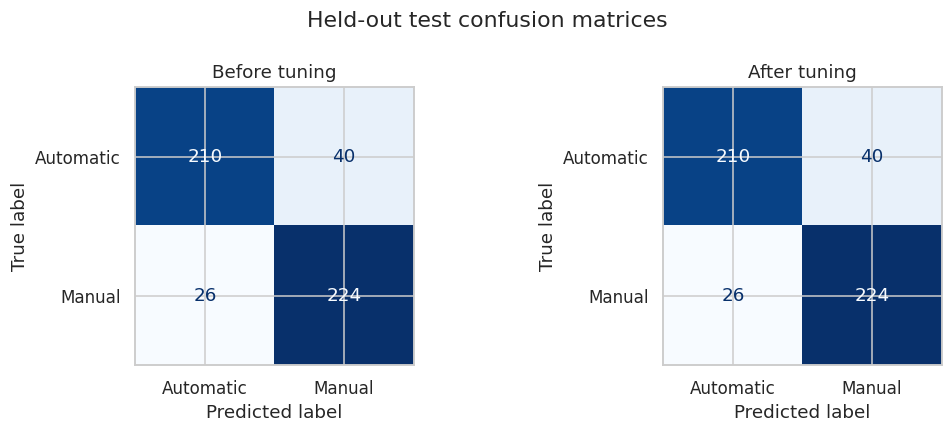

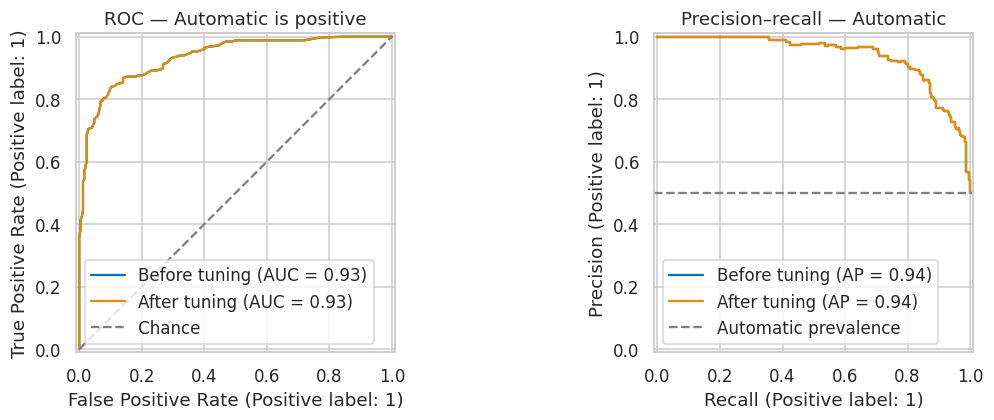

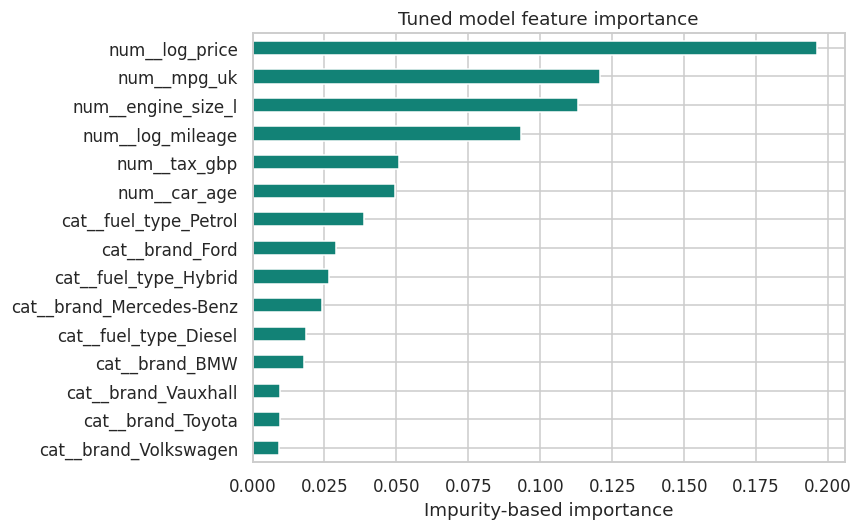

In [6]:
comparison = evaluate_pair(slug, name, baseline, tuned, X_test, y_test,
                           baseline_cv, search, warning_messages)
display(comparison.round(4))
metric_cols = ['Accuracy', 'F1_weighted', 'F1_macro', 'Automatic_recall', 'ROC_AUC', 'CV_macro_F1']
delta = comparison.loc[1, metric_cols] - comparison.loc[0, metric_cols]
display(delta.to_frame('After minus before'))
comparison.set_index('Stage')[['F1_macro', 'F1_weighted', 'Balanced_accuracy', 'ROC_AUC']].T.plot.bar(figsize=(9, 4), ylim=(0, 1))
plt.title('Before and after tuning: held-out metrics'); plt.xlabel('Metric'); plt.ylabel('Score')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()
display(pd.read_csv(ROOT / 'results' / slug / 'after_class_report.csv', index_col=0))
plot_pair(slug, baseline, tuned, X_test, y_test)


## Team interpretation and viva preparation
Complete these prompts yourself after inspecting the actual outputs:
- Which metric changed most, and by how much? Did test performance improve or decline?
- How many Automatic cars were missed before and after tuning?
- Why is oversampling unnecessary here? What does distinct listing data establish, and what does it not prove?
- Explain this model's training mechanism and the selected hyperparameters.
- Why might CV improvement fail to produce test improvement?

Models and numeric results are exported to `models/` and `results/`. The GUI reads those same files.
Source: [scikit-learn](https://scikit-learn.org/stable/). See data/CLASSIFICATION_DATA_SOURCE.md for dataset provenance.
AI-assisted code scaffolding is disclosed in README. Your interpretation must be original.
